# Repaired VAE music clustering project

This notebook inspects the completed experiments. The authoritative training code lives in `musicvae/`; the supplied notebooks are preserved as historical records. See the README for training commands. The bilingual study is a separate transductive course demonstration, not a held-out language benchmark.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd()
if not (ROOT / 'musicvae').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'results/rebuilt_v1/completion.json').exists()
print('Project:', ROOT)


Project: /Users/azmainfaysal/GitHub Uploads/VAE


## Data and splits
The 683-song corpus is aligned by saved IDs. Duplicate groups do not cross splits. Raw-audio provenance remains unresolved; no language labels are invented for this corpus.

In [2]:
manifest = json.loads((ROOT/'results/rebuilt_v1/manifest.json').read_text())
display(pd.DataFrame(manifest['split_genres']).fillna(0).astype(int))
print('Split sizes:', manifest['split_sizes'])


,train,val,test
rap,123,27,28
rock,117,30,31
pop,107,24,22
country,80,14,15
rb,51,8,6


Split sizes: {'train': 478, 'val': 103, 'test': 102}


## Main comparison
Primary results use training-fitted K-means to predict held-out songs. Oracles use true genre at inference and must be read separately. Standard deviations below reflect seeds on one fixed split.

ari           nmi        silhouette         \
                                mean    std   mean    std       mean    std   
method                                                                        
audio_ae                       0.072  0.010  0.119  0.023      0.292  0.024   
audio_pca                      0.086  0.000  0.128  0.000      0.236  0.000   
audio_statistics               0.084  0.003  0.121  0.008      0.264  0.003   
audio_vae_b001                 0.070  0.010  0.111  0.007      0.247  0.009   
audio_vae_b01                  0.096  0.020  0.128  0.017      0.218  0.016   
audio_vae_b1                   0.067  0.018  0.105  0.027      0.251  0.016   
audio_vae_b100                 0.067  0.012  0.106  0.011      0.435  0.023   
conditional_oracle             0.067  0.014  0.104  0.015      0.180  0.025   
conv_vae                       0.068  0.007  0.103  0.016      0.226  0.030   
direct_spectral                0.086  0.000  0.128  0.000      0.157  0.000   
fusion_pca                     0.089  0.010  0.119  0.005      0.236  0.006   
hybrid_vae                     0.207  0.029  0.241  0.037      0.149  0.041   
lyrics_lsa                     0.227  0.028  0.258  0.017      0.056  0.012   
multimodal_conditional_oracle  0.164  0.080  0.215  0.079      0.201  0.034   
multimodal_freebits            0.172  0.078  0.192  0.082      0.197  0.055   
multimodal_shuffled            0.032  0.012  0.066  0.015      0.149  0.024   
multimodal_vae                 0.153  0.096  0.177  0.094      0.195  0.038   

                              purity         
                                mean    std  
method                                       
audio_ae                       0.422  0.030  
audio_pca                      0.441  0.000  
audio_statistics               0.449  0.004  
audio_vae_b001                 0.406  0.005  
audio_vae_b01                  0.449  0.021  
audio_vae_b1                   0.420  0.024  
audio_vae_b100                 0.427  0.015  
conditional_oracle             0.396  0.023  
conv_vae                       0.418  0.021  
direct_spectral                0.441  0.000  
fusion_pca                     0.447  0.005  
hybrid_vae                     0.516  0.019  
lyrics_lsa                     0.541  0.013  
multimodal_conditional_oracle  0.484  0.068  
multimodal_freebits            0.476  0.059  
multimodal_shuffled            0.373  0.012  
multimodal_vae                 0.467  0.064

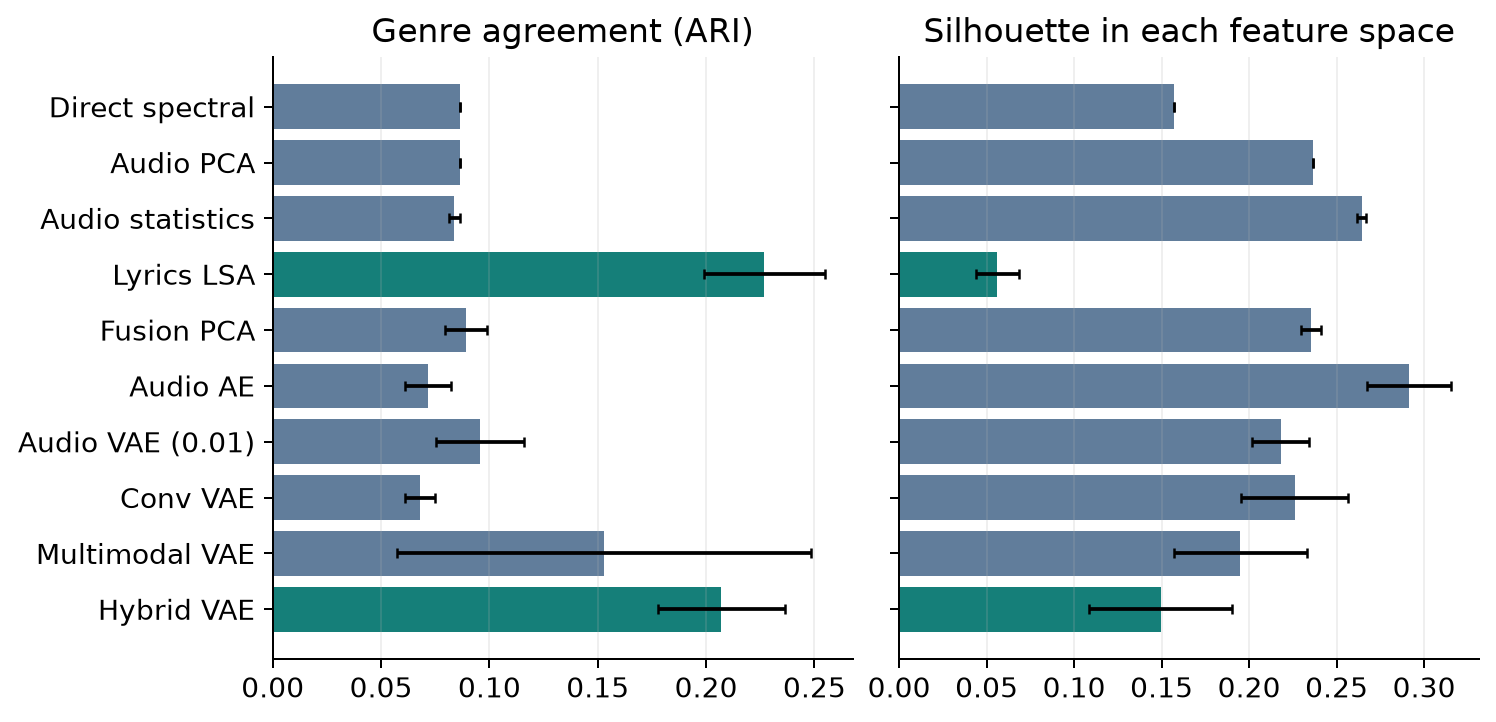

In [3]:
metrics = pd.concat([pd.read_csv(ROOT/'results/rebuilt_v1/metrics.csv'), pd.read_csv(ROOT/'results/requirements_extension/metrics.csv')])
heldout = metrics.query("split == 'test' and protocol == 'inductive_kmeans' and k_requested == 5")
display(heldout.groupby('method')[['ari','nmi','silhouette','purity']].agg(['mean','std']).round(3))
display(Image(filename=str(ROOT/'Final Writing Latex/figures/rebuilt_performance.png')))


## Controls and uncertainty
Shuffled text tests the importance of real song--lyric pairing. Free bits is an ablation, not a guaranteed improvement. Bootstrap intervals are exploratory and conditional on this test split.

,a,b,mean_difference,lower95,upper95,resamples
0,hybrid_vae,audio_vae_b01,0.111410,0.029645,0.195061,1000
1,hybrid_vae,lyrics_lsa,-0.019784,-0.126263,0.092400,1000
2,hybrid_vae,fusion_pca,0.117816,0.027311,0.210610,1000
3,multimodal_vae,multimodal_shuffled,0.121510,0.028147,0.243023,1000
4,multimodal_freebits,multimodal_vae,0.018788,-0.059521,0.095026,1000
5,audio_vae_b01,audio_pca,0.009262,-0.040063,0.059882,1000


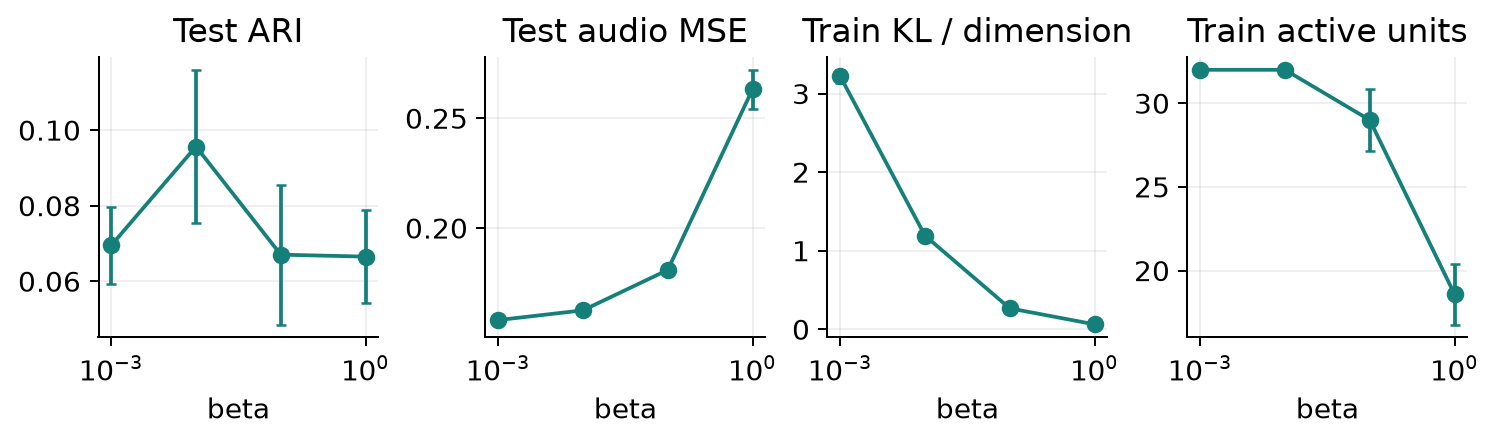

In [4]:
display(pd.read_json(ROOT/'results/analysis/paired_bootstrap.json'))
display(Image(filename=str(ROOT/'Final Writing Latex/figures/rebuilt_beta.png')))


## Follow-up split sensitivity
Two additional duplicate-group-disjoint splits repeat ten methods with five seeds. Hyperparameters are unchanged. The splits overlap within one corpus and are not independent datasets.

In [5]:
sensitivity = pd.read_csv(ROOT/'results/analysis/split_sensitivity_runs.csv')
display(sensitivity.groupby(['method','split_seed']).ari.agg(['mean','std']).round(3).unstack())
display(json.loads((ROOT/'audit/robustness_verification.json').read_text()))


mean                  std              
split_seed            2026   2027   2028   2026   2027   2028
method                                                       
audio_ae             0.072  0.059  0.024  0.010  0.041  0.016
audio_pca            0.086  0.064  0.001  0.000  0.006  0.002
audio_statistics     0.084  0.102  0.017  0.003  0.016  0.001
audio_vae_b01        0.096  0.102  0.044  0.020  0.012  0.013
conv_vae             0.068  0.084  0.012  0.007  0.017  0.005
fusion_pca           0.089  0.072  0.014  0.010  0.004  0.001
hybrid_vae           0.207  0.192  0.183  0.029  0.028  0.042
lyrics_lsa           0.227  0.277  0.272  0.028  0.033  0.031
multimodal_shuffled  0.032  0.025 -0.009  0.012  0.018  0.003
multimodal_vae       0.153  0.178  0.115  0.096  0.057  0.044

{'passed': True,
 'neural_checkpoints_reloaded': 60,
 'heldout_metrics_recomputed': 100,
 'metric_rows': 1600,
 'split_seeds': [2027, 2028],
 'source_and_data_hashes_verified': True,
 'split_groups_disjoint': True}

## Reconstructions and genre counts
These are feature-array reconstructions, not regenerated waveforms. The plots use a fixed sample-selection rule.

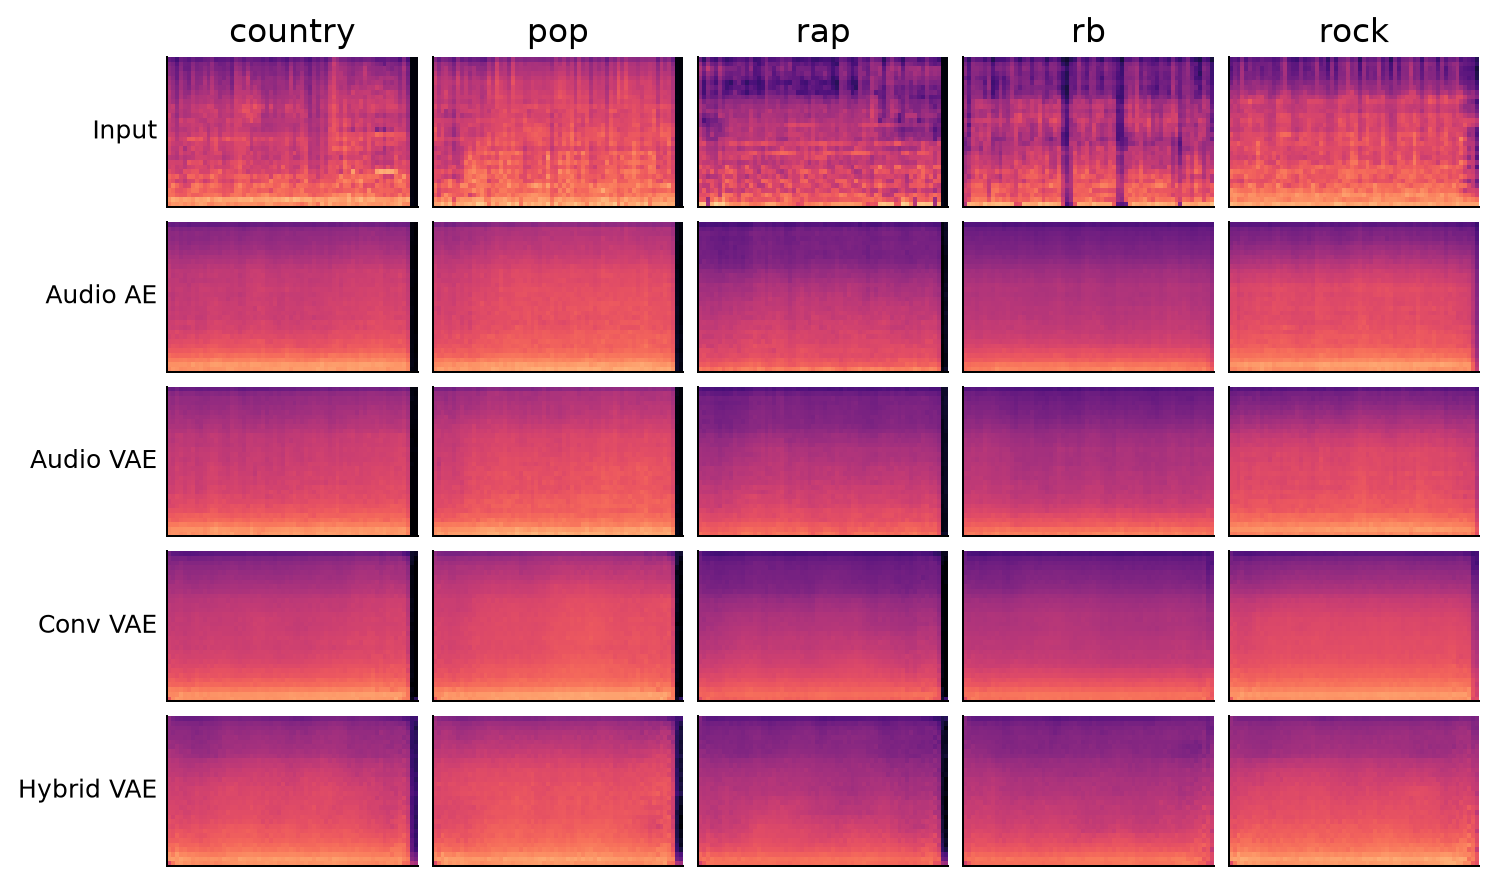

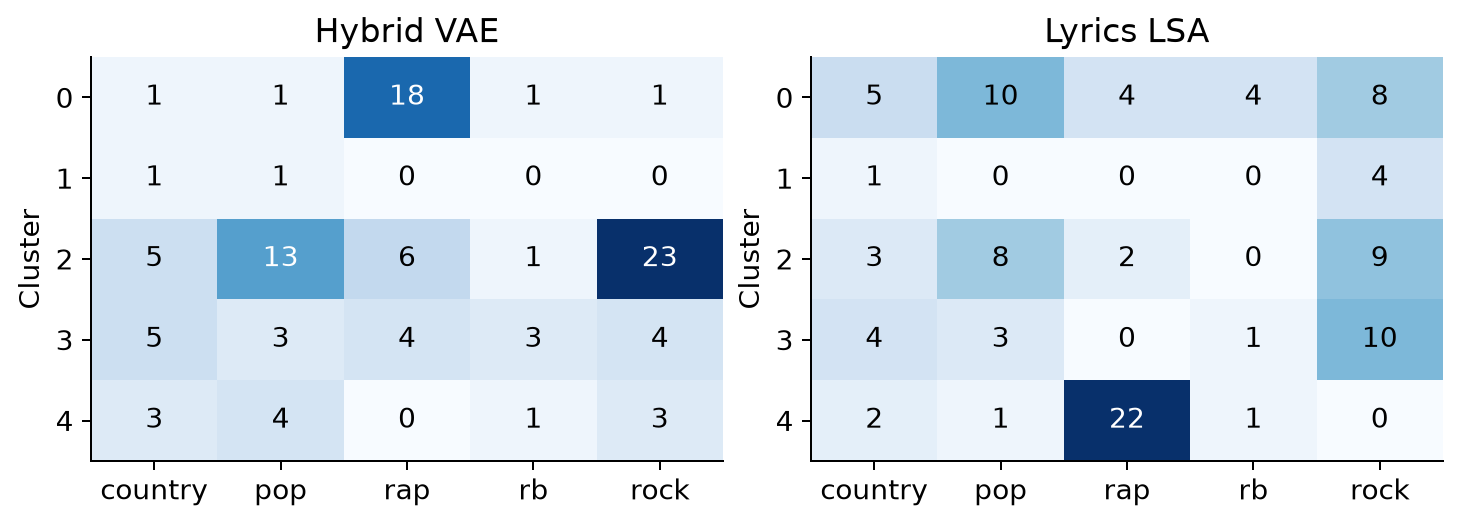

In [6]:
display(Image(filename=str(ROOT/'Final Writing Latex/figures/rebuilt_reconstruction.png')))
display(Image(filename=str(ROOT/'Final Writing Latex/figures/rebuilt_genre_distribution.png')))


## Bilingual Easy-task demonstration
20 English recordings and 20 Bengali clips are processed identically. Language and collection source are perfectly confounded. K-means fits and scores all 40 clips; these are descriptive metrics, not held-out generalization scores.

silhouette        calinski_harabasz           ari       
               mean    std              mean    std   mean    std
method k                                                         
PCA    2      0.273  0.000            19.125  0.038  0.008  0.010
       5      0.175  0.026            10.025  0.222  0.003  0.010
VAE    2      0.478  0.009            57.363  5.213 -0.001  0.015
       5      0.376  0.023            54.907  5.140 -0.005  0.011

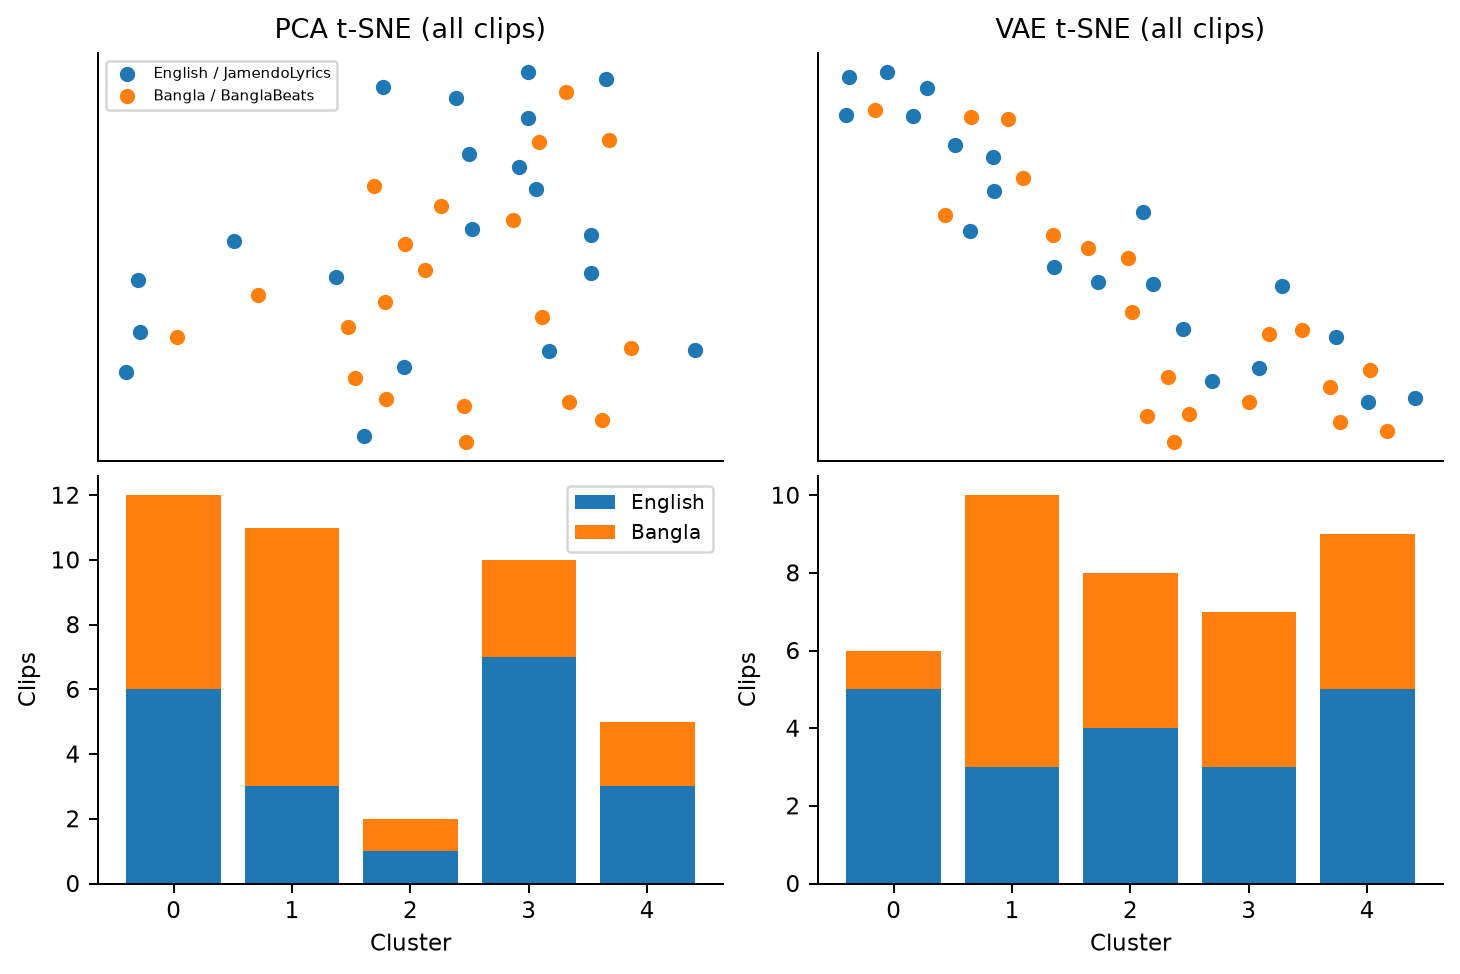

In [7]:
bilingual = pd.read_csv(ROOT/'results/bilingual/metrics.csv')
display(bilingual.groupby(['method','k'])[['silhouette','calinski_harabasz','ari']].agg(['mean','std']).round(3))
display(Image(filename=str(ROOT/'Final Writing Latex/figures/bilingual.png')))


## Verification and next research steps
Read `COURSE_REQUIREMENTS.md`, `DATA_CARD.md`, and `CONFERENCE_READINESS.md`. The revised report does not claim novel architecture, proven disentanglement, or conference acceptance.

In [8]:
display(json.loads((ROOT/'audit/verification.json').read_text()))
print('Paper:', ROOT/'Final Writing Latex/neurips_2024.pdf')


{'passed': True,
 'input_hashes_verified': 4,
 'core_source_hashes_verified': 5,
 'main_and_extension_checkpoints_reloaded': 60,
 'heldout_clustering_results_recomputed': 85,
 'bilingual_checkpoints_reloaded': 5,
 'bilingual_vae_metrics_recomputed': 10,
 'bilingual_recording_hashes_verified': 40,
 'split_groups_disjoint': True,
 'raw_metric_rows': 1380}

Paper: /Users/azmainfaysal/GitHub Uploads/VAE/Final Writing Latex/neurips_2024.pdf
